## Visualización de los clusters

Las transacciones tienen 36 variables (las del modelo ya transformadas: logaritmos, hora y día codificados con seno y coseno), así que no se pueden dibujar directamente. Se usa PCA para proyectarlas a 2 dimensiones: busca el plano donde los datos quedan más separados y aplasta el resto. Es como fotografiar un objeto 3D desde el ángulo en el que mejor se distingue su forma; se pierde información, pero se ve la estructura.

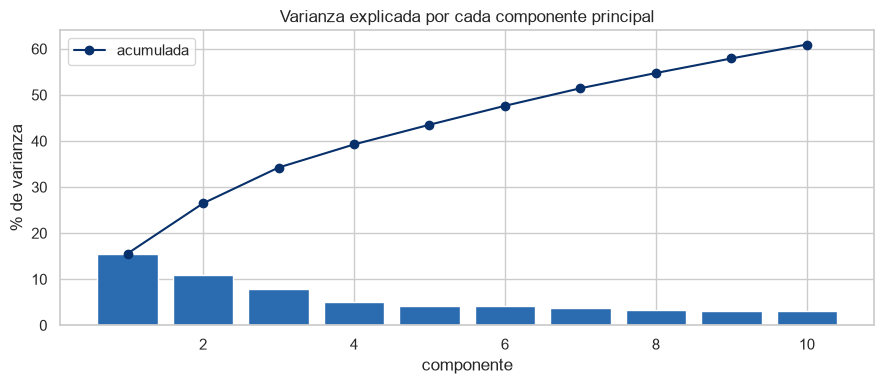

Las 2 primeras componentes explican el 26.5 % de la varianza


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from matplotlib.lines import Line2D
from sklearn.decomposition import PCA
import sys
sys.path.insert(0, '..')

AZUL = "#2b6cb0"
sns.set_theme(style="whitegrid")

X_train = pd.read_parquet("../datos_ml/X_train.parquet")
modelo = joblib.load("../modelos/kmeans.joblib")
scores = pd.read_parquet("../modelos/kmeans_scores_train.parquet")
cluster = scores["cluster"].values
distancia = scores["score"].values   # el score de KMeans es la distancia al centroide más cercano
# k se elige en el entrenamiento (rejilla de config.yaml): un color por cluster, sea cual sea k
K = modelo.n_clusters
COLORES = sns.color_palette("Blues", K + 2)[2:]

pca = PCA(n_components=10, random_state=42).fit(X_train)
var = pca.explained_variance_ratio_ * 100

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(range(1, 11), var, color=AZUL)
ax.plot(range(1, 11), np.cumsum(var), color="#08306b", marker="o", label="acumulada")
ax.set_title("Varianza explicada por cada componente principal")
ax.set_xlabel("componente")
ax.set_ylabel("% de varianza")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Las 2 primeras componentes explican el {var[:2].sum():.1f} % de la varianza")

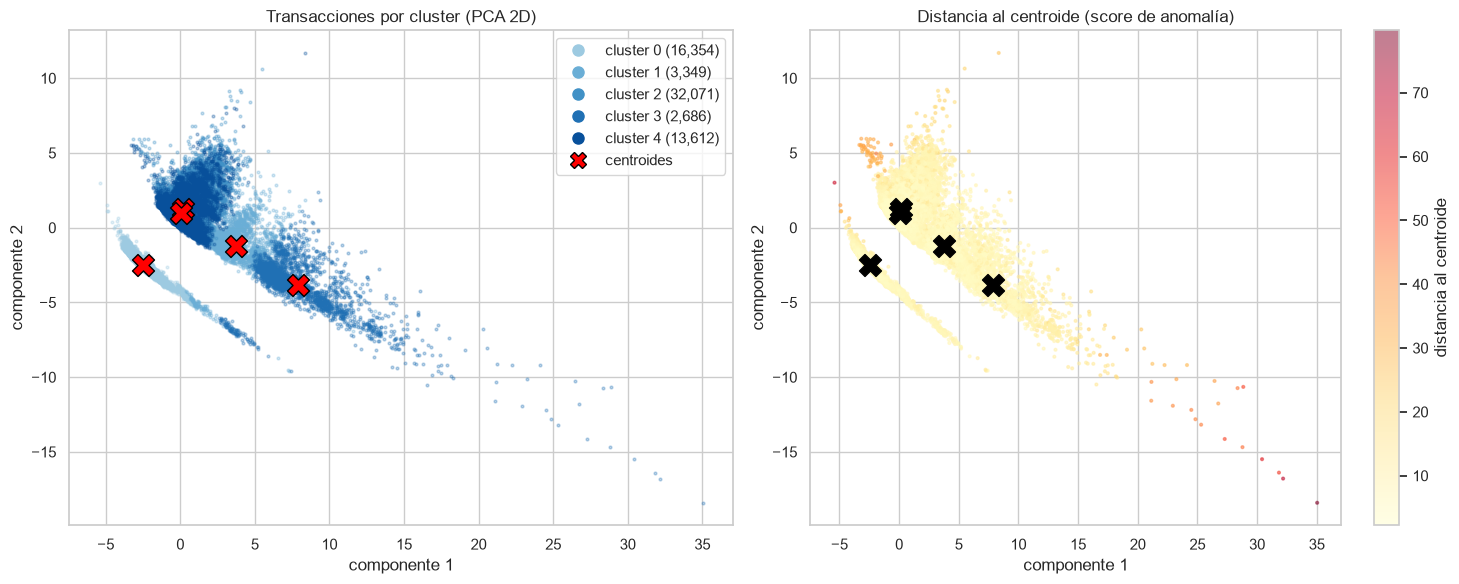

In [2]:
proyeccion = PCA(n_components=2, random_state=42).fit(X_train)
P = proyeccion.transform(X_train)
cen = proyeccion.transform(pd.DataFrame(modelo.cluster_centers_, columns=X_train.columns))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for c in range(K):
    m = cluster == c
    axes[0].scatter(P[m, 0], P[m, 1], s=4, alpha=0.3, color=COLORES[c])
axes[0].scatter(cen[:, 0], cen[:, 1], marker="X", s=250, color="red", edgecolor="black", zorder=5)
axes[0].set_title("Transacciones por cluster (PCA 2D)")
axes[0].set_xlabel("componente 1")
axes[0].set_ylabel("componente 2")
# leyenda aparte: los puntos reales son diminutos y no se verían
handles = [Line2D([], [], marker="o", linestyle="", color=COLORES[c], markersize=8,
                  label=f"cluster {c} ({(cluster == c).sum():,})") for c in range(K)]
handles.append(Line2D([], [], marker="X", linestyle="", color="red", markeredgecolor="black",
                      markersize=12, label="centroides"))
axes[0].legend(handles=handles)

s = axes[1].scatter(P[:, 0], P[:, 1], c=distancia, s=4, alpha=0.5, cmap="YlOrRd")
axes[1].scatter(cen[:, 0], cen[:, 1], marker="X", s=250, color="black", zorder=5)
plt.colorbar(s, ax=axes[1], label="distancia al centroide")
axes[1].set_title("Distancia al centroide (score de anomalía)")
axes[1].set_xlabel("componente 1")
axes[1].set_ylabel("componente 2")

plt.tight_layout()
plt.show()

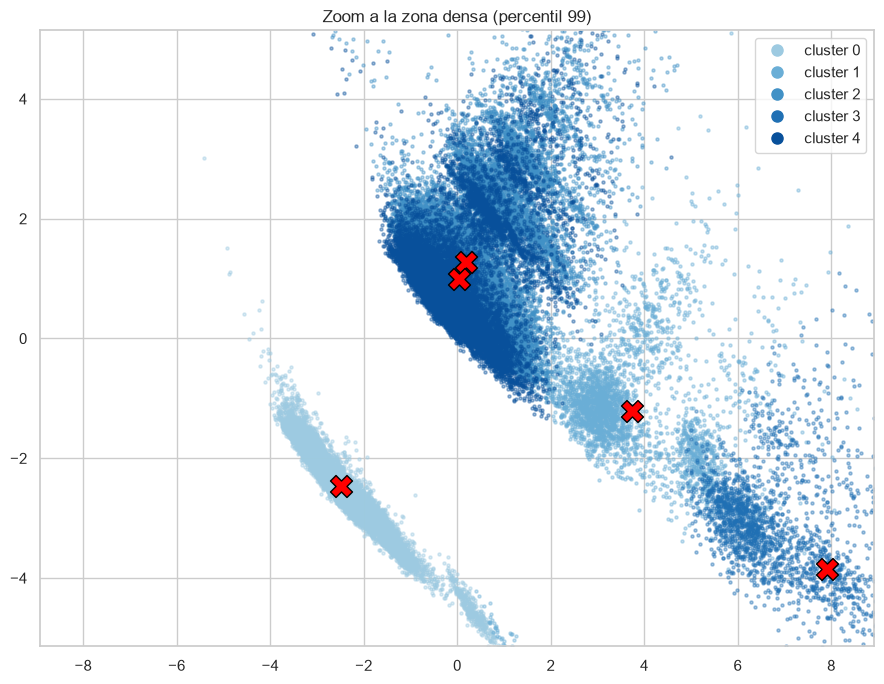

In [3]:
lim = np.percentile(np.abs(P), 99, axis=0)

fig, ax = plt.subplots(figsize=(9, 7))
for c in range(K):
    m = cluster == c
    ax.scatter(P[m, 0], P[m, 1], s=5, alpha=0.4, color=COLORES[c])
ax.scatter(cen[:, 0], cen[:, 1], marker="X", s=250, color="red", edgecolor="black", zorder=5)
ax.set_xlim(-lim[0], lim[0])
ax.set_ylim(-lim[1], lim[1])
ax.set_title("Zoom a la zona densa (percentil 99)")
ax.legend(handles=[Line2D([], [], marker="o", linestyle="", color=COLORES[c], markersize=8,
                          label=f"cluster {c}") for c in range(K)])
plt.tight_layout()
plt.show()

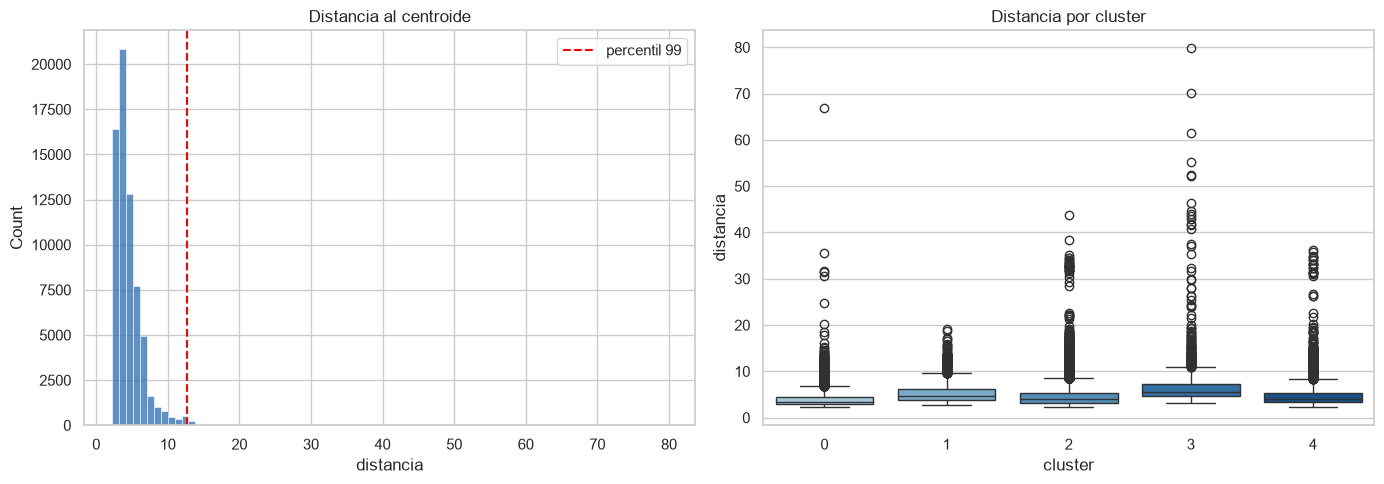

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(distancia, bins=80, color=AZUL, ax=axes[0])
axes[0].axvline(np.percentile(distancia, 99), color="red", linestyle="--", label="percentil 99")
axes[0].set_title("Distancia al centroide")
axes[0].set_xlabel("distancia")
axes[0].legend()

sns.boxplot(x=cluster, y=distancia, hue=cluster, palette=COLORES, legend=False, ax=axes[1])
axes[1].set_title("Distancia por cluster")
axes[1].set_xlabel("cluster")
axes[1].set_ylabel("distancia")

plt.tight_layout()
plt.show()